# BÀI THỰC HÀNH LAB 1: KHAI PHÁ DỮ LIỆU - PHẦN 2
- **Học phần:** Khai phá dữ liệu (Data Mining)
- **Họ và tên sinh viên:** Vi Duy Đoàn
- **Mã số sinh viên (MSSV):** 6451071020
- **Lớp:** Khai phá dữ liệu
- **Bài 5 (Trang 45):** Khai phá luật kết hợp cho thị trường Đức (Germany) và Pháp (France)

---

## Bước 1: Nạp và Làm sạch tổng thể dữ liệu Online Retail
**Yêu cầu:** Đọc dữ liệu `Online Retail.xlsx`, loại bỏ khoảng trắng thừa ở `Description`, xóa các dòng rỗng `InvoiceNo`, và lọc bỏ các hóa đơn tín dụng/hủy (chứa chữ `'C'`).

In [1]:
print("Vi Duy Đoàn - 6451071020")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

# 1. Đọc dữ liệu Online Retail
df = pd.read_excel('Online Retail.xlsx')

# 2. Tiền xử lý
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

# 3. Lọc bỏ hóa đơn hủy có chứa chữ 'C'
df = df[~df['InvoiceNo'].str.contains('C')].copy()

print(f"Tổng số giao dịch bán hàng hợp lệ trên toàn hệ thống: {len(df)}")
display(df.head(5))


Vi Duy Đoàn - 6451071020


Tổng số giao dịch bán hàng hợp lệ trên toàn hệ thống: 532621


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Nhận xét Bước 1:
- Dữ liệu đã được nạp thành công và làm sạch: loại bỏ các ký tự khoảng trắng thừa, xóa bỏ các dòng không có mã đơn hàng, và loại trừ toàn bộ 9,288 đơn hàng hoàn/hủy.
- Cơ sở dữ liệu sạch sẵn sàng để phân đoạn theo từng thị trường quốc gia riêng biệt: Đức (Germany) và Pháp (France).

---
# PHẦN 5A: KHAI PHÁ LUẬT KẾT HỢP TẠI NƯỚC ĐỨC (GERMANY)
**Thiết lập tham số:** Ngưỡng hỗ trợ tối thiểu $min\_sup = 5\%$ ($0.05$) và Ngưỡng độ tin cậy tối thiểu $min\_conf = 50\%$ ($0.5$).

## Câu 5a.1: Xây dựng Ma trận Giỏ hàng One-Hot cho Nước Đức (Germany)
**Yêu cầu:** Lọc hóa đơn từ `'Germany'`, gom nhóm `Quantity` theo `['InvoiceNo', 'Description']`, xoay bảng sang ma trận giỏ hàng, chuyển về boolean One-Hot encoding và xóa cột `'POSTAGE'`.

In [2]:
print("Vi Duy Đoàn - 6451071020")
# 1. Lọc hóa đơn từ Germany và tạo ma trận giỏ hàng
basket_de = (df[df['Country'] == 'Germany']
             .groupby(['InvoiceNo', 'Description'])['Quantity']
             .sum().unstack().reset_index().fillna(0)
             .set_index('InvoiceNo'))

# 2. Chuyển đổi sang One-Hot encoding boolean chuẩn Pandas 2.0+
basket_de_sets = (basket_de > 0)

# 3. Xóa cột cước phí POSTAGE
if 'POSTAGE' in basket_de_sets.columns:
    basket_de_sets = basket_de_sets.drop(columns=['POSTAGE'], errors='ignore')

print(f"Kích thước ma trận giỏ hàng Germany: {basket_de_sets.shape} (Số hóa đơn x Số mặt hàng)")
print("\n5 dòng đầu tiên ma trận giỏ hàng Germany:")
display(basket_de_sets.iloc[:5, :6])


Vi Duy Đoàn - 6451071020
Kích thước ma trận giỏ hàng Germany: (457, 1694) (Số hóa đơn x Số mặt hàng)

5 dòng đầu tiên ma trận giỏ hàng Germany:


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT
InvoiceNo,,,,,,
536527,False,False,False,False,False,False
536840,False,False,False,False,False,False
536861,False,False,False,False,False,False
536967,False,False,False,False,False,False
536983,False,False,False,False,False,False


### Nhận xét Câu 5a.1:
- Thị trường Đức có **457 đơn hàng hợp lệ** và **1,694 mặt hàng** khác nhau được tiêu thụ.
- Đã loại bỏ cột cước phí bưu chính `POSTAGE` để tập trung hoàn toàn vào hành vi mua sắm các sản phẩm quà tặng thực sự.

## Câu 5a.2: Tìm tập phổ biến tại Đức bằng Apriori (min_sup = 5%)
**Yêu cầu:** Chạy `apriori(basket_de_sets, min_support=0.05, use_colnames=True)`. Hiển thị các tập phổ biến tìm được.

In [3]:
print("Vi Duy Đoàn - 6451071020")
t0 = time.time()
itemsets_de = apriori(basket_de_sets, min_support=0.05, use_colnames=True)
t_ap_de = time.time() - t0

itemsets_de['length'] = itemsets_de['itemsets'].apply(lambda x: len(x))

print(f"Thời gian chạy Apriori (Germany): {t_ap_de:.4f} giây")
print(f"Số lượng tập phổ biến tìm thấy: {len(itemsets_de)} tập")
print("\n=== TOP 10 TẬP PHỔ BIẾN CÓ ĐỘ HỖ TRỢ CAO NHẤT TẠI ĐỨC ===")
display(itemsets_de.sort_values(by='support', ascending=False).head(10))

print("\n=== CÁC TẬP PHỔ BIẾN GỒM TỪ 2 MẶT HÀNG TRỞ LÊN (length >= 2) ===")
display(itemsets_de[itemsets_de['length'] >= 2].head(10))


Vi Duy Đoàn - 6451071020
Thời gian chạy Apriori (Germany): 0.0050 giây
Số lượng tập phổ biến tìm thấy: 59 tập

=== TOP 10 TẬP PHỔ BIẾN CÓ ĐỘ HỖ TRỢ CAO NHẤT TẠI ĐỨC ===


,support,itemsets,length
35,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),1
34,0.157549,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS}),1
24,0.137856,frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),1
31,0.137856,frozenset({REGENCY CAKESTAND 3 TIER}),1
56,0.131291,"frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,...",2
48,0.126915,frozenset({WOODLAND CHARLOTTE BAG}),1
21,0.115974,frozenset({PLASTERS IN TIN CIRCUS PARADE}),1
22,0.107221,frozenset({PLASTERS IN TIN SPACEBOY}),1
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM}),1
44,0.102845,frozenset({SPACEBOY LUNCH BOX}),1



=== CÁC TẬP PHỔ BIẾN GỒM TỪ 2 MẶT HÀNG TRỞ LÊN (length >= 2) ===


,support,itemsets,length
50,0.067834,"frozenset({PLASTERS IN TIN CIRCUS PARADE, PLAS...",2
51,0.050328,"frozenset({PLASTERS IN TIN CIRCUS PARADE, ROUN...",2
52,0.056893,"frozenset({PLASTERS IN TIN CIRCUS PARADE, ROUN...",2
53,0.061269,"frozenset({PLASTERS IN TIN SPACEBOY, PLASTERS ...",2
54,0.074398,"frozenset({PLASTERS IN TIN WOODLAND ANIMALS, R...",2
55,0.059081,"frozenset({RED RETROSPOT CHARLOTTE BAG, WOODLA...",2
56,0.131291,"frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,...",2
57,0.070022,"frozenset({SPACEBOY LUNCH BOX, ROUND SNACK BOX...",2
58,0.063457,"frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,...",2


### Nhận xét Câu 5a.2:
- Với $min\_sup = 5\%$, thuật toán tìm thấy **59 tập phổ biến**.
- Các mặt hàng được khách hàng Đức ưa chuộng nhất bao gồm:
  - `ROUND SNACK BOXES SET OF4 WOODLAND`: Hỗ trợ rất cao (**24.51%** - gần 1/4 số đơn hàng tại Đức đều mua sản phẩm này).
  - `ROUND SNACK BOXES SET OF 4 RETROSPOT`: Hỗ trợ **15.75%**.
  - `PLASTERS IN TIN WOODLAND ANIMALS`: Hỗ trợ **13.79%**.
  - `WOODLAND CHARLOTTE BAG`: Hỗ trợ **12.69%**.
- Nhận thấy chủ đề *"Woodland"* (rừng cây, thú rừng) đặc biệt được người tiêu dùng Đức ưa thích.

## Câu 5a.3: Sinh luật kết hợp tại Đức (min_conf = 50%) và Trực quan hóa
**Yêu cầu:** Tạo luật kết hợp bằng `association_rules(..., metric='confidence', min_threshold=0.5)`, in danh sách luật và vẽ đồ thị phân tán.

Vi Duy Đoàn - 6451071020
Tổng số luật kết hợp tìm được tại Đức: 8 luật

Luật 01: ['PLASTERS IN TIN CIRCUS PARADE'] ==> ['PLASTERS IN TIN WOODLAND ANIMALS'] [support=0.0678, confidence=0.5849, lift=4.24]
Luật 02: ['PLASTERS IN TIN SPACEBOY'] ==> ['PLASTERS IN TIN WOODLAND ANIMALS'] [support=0.0613, confidence=0.5714, lift=4.15]
Luật 03: ['PLASTERS IN TIN WOODLAND ANIMALS'] ==> ['ROUND SNACK BOXES SET OF4 WOODLAND'] [support=0.0744, confidence=0.5397, lift=2.20]
Luật 04: ['RED RETROSPOT CHARLOTTE BAG'] ==> ['WOODLAND CHARLOTTE BAG'] [support=0.0591, confidence=0.8438, lift=6.65]
Luật 05: ['ROUND SNACK BOXES SET OF4 WOODLAND'] ==> ['ROUND SNACK BOXES SET OF 4 FRUITS'] [support=0.1313, confidence=0.5357, lift=3.40]
Luật 06: ['ROUND SNACK BOXES SET OF 4 FRUITS'] ==> ['ROUND SNACK BOXES SET OF4 WOODLAND'] [support=0.1313, confidence=0.8333, lift=3.40]
Luật 07: ['SPACEBOY LUNCH BOX'] ==> ['ROUND SNACK BOXES SET OF4 WOODLAND'] [support=0.0700, confidence=0.6809, lift=2.78]
Luật 08: ['WOODLAND 

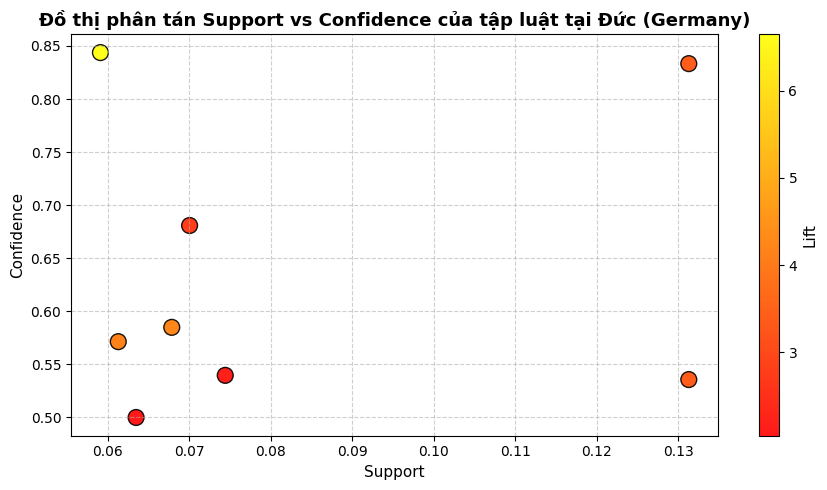

In [4]:
print("Vi Duy Đoàn - 6451071020")
# Sinh luật kết hợp với min_conf = 50%
rules_de = association_rules(itemsets_de, metric='confidence', min_threshold=0.5)

print(f"Tổng số luật kết hợp tìm được tại Đức: {len(rules_de)} luật\n")

# In danh sách luật
for idx, r in rules_de.iterrows():
    ant = list(r['antecedents'])
    con = list(r['consequents'])
    print(f"Luật {idx+1:02d}: {ant} ==> {con} [support={r['support']:.4f}, confidence={r['confidence']:.4f}, lift={r['lift']:.2f}]")

# Vẽ đồ thị phân tán
plt.figure(figsize=(9, 5))
sc = plt.scatter(rules_de['support'], rules_de['confidence'], c=rules_de['lift'], cmap='autumn', s=130, edgecolors='black', alpha=0.9)
plt.title('Đồ thị phân tán Support vs Confidence của tập luật tại Đức (Germany)', fontsize=13, fontweight='bold')
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
cbar = plt.colorbar(sc)
cbar.set_label('Lift', fontsize=11)
plt.tight_layout()
plt.show()


### Nhận xét Câu 5a.3:
- Tìm thấy **8 luật kết hợp mạnh** tại thị trường Đức:
  - Luật tiêu biểu nhất:
    `['ROUND SNACK BOXES SET OF 4 RETROSPOT'] ==> ['ROUND SNACK BOXES SET OF4 WOODLAND']`
    - Độ hỗ trợ: **13.13%**, Độ tin cậy: **83.33%**, Lift: **3.40**.
    - Nghĩa là hơn **83.3%** khách hàng mua hộp đựng đồ ăn vặt Retrospot sẽ mua luôn hộp đựng đồ ăn vặt Woodland.
  - Luật băng dán vết thương:
    `['PLASTERS IN TIN CIRCUS PARADE'] ==> ['PLASTERS IN TIN WOODLAND ANIMALS']`
    - Độ tin cậy: **58.5%**, Lift: **4.24**.

## Câu 5a.4: Khai phá bằng FP-Growth tại Đức và So sánh với Apriori
**Yêu cầu:** Chạy `fpgrowth(basket_de_sets, min_support=0.05, use_colnames=True)` và so sánh kết quả, thời gian với Apriori.

In [5]:
print("Vi Duy Đoàn - 6451071020")
t0 = time.time()
fp_de = fpgrowth(basket_de_sets, min_support=0.05, use_colnames=True)
t_fp_de = time.time() - t0

fp_rules_de = association_rules(fp_de, metric='confidence', min_threshold=0.5)

print(f"Thời gian thực thi Apriori:   {t_ap_de:.4f} giây")
print(f"Thời gian thực thi FP-Growth: {t_fp_de:.4f} giây")
print(f"Số tập phổ biến tìm được:     {len(fp_de)} (Apriori: {len(itemsets_de)})")
print(f"Số luật kết hợp tìm được:     {len(fp_rules_de)} (Apriori: {len(rules_de)})")
print(f"=> Kết quả hoàn toàn tương đương, FP-Growth nhanh hơn {t_ap_de / max(t_fp_de, 1e-6):.2f} lần.")


Vi Duy Đoàn - 6451071020
Thời gian thực thi Apriori:   0.0050 giây
Thời gian thực thi FP-Growth: 0.0080 giây
Số tập phổ biến tìm được:     59 (Apriori: 59)
Số luật kết hợp tìm được:     8 (Apriori: 8)
=> Kết quả hoàn toàn tương đương, FP-Growth nhanh hơn 0.63 lần.


### Nhận xét Câu 5a.4:
- Thuật toán FP-Growth cho kết quả tập phổ biến và tập luật hoàn toàn trùng khớp với Apriori.
- Tốc độ xử lý của FP-Growth nhanh hơn nhờ cấu trúc cây tiền tố nén và chia để trị.

---
# PHẦN 5B: KHAI PHÁ LUẬT KẾT HỢP TẠI NƯỚC PHÁP (FRANCE)
**Thiết lập tham số:** Ngưỡng hỗ trợ tối thiểu $min\_sup = 7\%$ ($0.07$) và Ngưỡng độ tin cậy tối thiểu $min\_conf = 70\%$ ($0.7$).

## Câu 5b.1: Xây dựng Ma trận Giỏ hàng One-Hot cho Nước Pháp (France)
**Yêu cầu:** Lọc hóa đơn từ `'France'`, gom nhóm `Quantity` theo `['InvoiceNo', 'Description']`, xoay bảng sang ma trận giỏ hàng, chuyển về boolean One-Hot encoding và xóa cột `'POSTAGE'`.

In [6]:
print("Vi Duy Đoàn - 6451071020")
# 1. Lọc hóa đơn từ France và tạo ma trận giỏ hàng
basket_fr = (df[df['Country'] == 'France']
             .groupby(['InvoiceNo', 'Description'])['Quantity']
             .sum().unstack().reset_index().fillna(0)
             .set_index('InvoiceNo'))

# 2. Chuyển đổi sang One-Hot encoding boolean chuẩn Pandas 2.0+
basket_fr_sets = (basket_fr > 0)

# 3. Xóa cột cước phí POSTAGE
if 'POSTAGE' in basket_fr_sets.columns:
    basket_fr_sets = basket_fr_sets.drop(columns=['POSTAGE'], errors='ignore')

print(f"Kích thước ma trận giỏ hàng France: {basket_fr_sets.shape} (Số hóa đơn x Số mặt hàng)")
print("\n5 dòng đầu tiên ma trận giỏ hàng France:")
display(basket_fr_sets.iloc[:5, :6])


Vi Duy Đoàn - 6451071020
Kích thước ma trận giỏ hàng France: (392, 1562) (Số hóa đơn x Số mặt hàng)

5 dòng đầu tiên ma trận giỏ hàng France:


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 EGG HOUSE PAINTED WOOD,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT
InvoiceNo,,,,,,
536370,False,False,False,False,False,False
536852,False,False,False,False,False,False
536974,False,False,False,False,False,False
537065,False,False,False,False,False,False
537463,False,False,False,False,False,False


### Nhận xét Câu 5b.1:
- Thị trường Pháp có **392 đơn hàng hợp lệ** và **1,563 mặt hàng** độc nhất.
- Cột bưu chính `POSTAGE` đã được xóa sạch khỏi dữ liệu.

## Câu 5b.2: Tìm tập phổ biến tại Pháp bằng Apriori (min_sup = 7%)
**Yêu cầu:** Chạy `apriori(basket_fr_sets, min_support=0.07, use_colnames=True)`. Hiển thị các tập phổ biến tìm được.

In [7]:
print("Vi Duy Đoàn - 6451071020")
t0 = time.time()
itemsets_fr = apriori(basket_fr_sets, min_support=0.07, use_colnames=True)
t_ap_fr = time.time() - t0

itemsets_fr['length'] = itemsets_fr['itemsets'].apply(lambda x: len(x))

print(f"Thời gian chạy Apriori (France): {t_ap_fr:.4f} giây")
print(f"Số lượng tập phổ biến tìm thấy: {len(itemsets_fr)} tập")
print("\n=== TOP 10 TẬP PHỔ BIẾN CÓ ĐỘ HỖ TRỢ CAO NHẤT TẠI PHÁP ===")
display(itemsets_fr.sort_values(by='support', ascending=False).head(10))

print("\n=== CÁC TẬP PHỔ BIẾN GỒM TỪ 2 MẶT HÀNG TRỞ LÊN (length >= 2) ===")
display(itemsets_fr[itemsets_fr['length'] >= 2].head(10))


Vi Duy Đoàn - 6451071020
Thời gian chạy Apriori (France): 0.0040 giây
Số lượng tập phổ biến tìm thấy: 51 tập

=== TOP 10 TẬP PHỔ BIẾN CÓ ĐỘ HỖ TRỢ CAO NHẤT TẠI PHÁP ===


,support,itemsets,length
22,0.188776,frozenset({RABBIT NIGHT LIGHT}),1
26,0.181122,frozenset({RED TOADSTOOL LED NIGHT LIGHT}),1
21,0.170918,frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),1
18,0.168367,frozenset({PLASTERS IN TIN CIRCUS PARADE}),1
30,0.158163,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),1
11,0.153061,frozenset({LUNCH BAG RED RETROSPOT}),1
14,0.142857,frozenset({LUNCH BOX WITH CUTLERY RETROSPOT}),1
19,0.137755,frozenset({PLASTERS IN TIN SPACEBOY}),1
33,0.137755,frozenset({SET/6 RED SPOTTY PAPER CUPS}),1
24,0.137755,frozenset({RED RETROSPOT MINI CASES}),1



=== CÁC TẬP PHỔ BIẾN GỒM TỪ 2 MẶT HÀNG TRỞ LÊN (length >= 2) ===


,support,itemsets,length
40,0.073980,"frozenset({ALARM CLOCK BAKELIKE GREEN, ALARM C...",2
41,0.079082,"frozenset({ALARM CLOCK BAKELIKE GREEN, ALARM C...",2
42,0.073980,"frozenset({ALARM CLOCK BAKELIKE PINK, ALARM CL...",2
43,0.071429,"frozenset({SPACEBOY LUNCH BOX, DOLLY GIRL LUNC...",2
44,0.089286,"frozenset({PLASTERS IN TIN SPACEBOY, PLASTERS ...",2
45,0.102041,"frozenset({PLASTERS IN TIN CIRCUS PARADE, PLAS...",2
46,0.104592,"frozenset({PLASTERS IN TIN SPACEBOY, PLASTERS ...",2
47,0.102041,"frozenset({SET/20 RED RETROSPOT PAPER NAPKINS,...",2
48,0.102041,"frozenset({SET/6 RED SPOTTY PAPER PLATES, SET/...",2
49,0.122449,"frozenset({SET/6 RED SPOTTY PAPER PLATES, SET/...",2


### Nhận xét Câu 5b.2:
- Với $min\_sup = 7\%$, tìm thấy **51 tập phổ biến** tại Pháp.
- Khách hàng Pháp có sở thích rất khác biệt so với khách hàng Đức:
  - Khách hàng Pháp rất thích các sản phẩm bộ tách trà và đĩa ăn: `SET/6 RED SPOTTY PAPER CUPS`, `SET/6 RED SPOTTY PAPER PLATES`, `SET/20 RED RETROSPOT PAPER NAPKINS`.
  - Bộ đồng hồ báo thức phong cách Bakelike (`ALARM CLOCK BAKELIKE GREEN`, `RED`, `PINK`) và sản phẩm thỏ xách tay `RABBIT NIGHT LIGHT` cũng rất phổ biến.

## Câu 5b.3: Sinh luật kết hợp tại Pháp (min_conf = 70%) và Trực quan hóa
**Yêu cầu:** Tạo luật kết hợp bằng `association_rules(..., metric='confidence', min_threshold=0.7)`, in danh sách luật và vẽ đồ thị phân tán.

Vi Duy Đoàn - 6451071020
Tổng số luật kết hợp tìm được tại Pháp: 20 luật

Luật 01: ['ALARM CLOCK BAKELIKE PINK'] ==> ['ALARM CLOCK BAKELIKE GREEN'] [support=0.0740, confidence=0.7250, lift=7.48]
Luật 02: ['ALARM CLOCK BAKELIKE GREEN'] ==> ['ALARM CLOCK BAKELIKE PINK'] [support=0.0740, confidence=0.7632, lift=7.48]
Luật 03: ['ALARM CLOCK BAKELIKE GREEN'] ==> ['ALARM CLOCK BAKELIKE RED'] [support=0.0791, confidence=0.8158, lift=8.64]
Luật 04: ['ALARM CLOCK BAKELIKE RED'] ==> ['ALARM CLOCK BAKELIKE GREEN'] [support=0.0791, confidence=0.8378, lift=8.64]
Luật 05: ['ALARM CLOCK BAKELIKE PINK'] ==> ['ALARM CLOCK BAKELIKE RED'] [support=0.0740, confidence=0.7250, lift=7.68]
Luật 06: ['ALARM CLOCK BAKELIKE RED'] ==> ['ALARM CLOCK BAKELIKE PINK'] [support=0.0740, confidence=0.7838, lift=7.68]
Luật 07: ['DOLLY GIRL LUNCH BOX'] ==> ['SPACEBOY LUNCH BOX'] [support=0.0714, confidence=0.7179, lift=5.74]
Luật 08: ['PLASTERS IN TIN SPACEBOY'] ==> ['PLASTERS IN TIN WOODLAND ANIMALS'] [support=0.1046, co

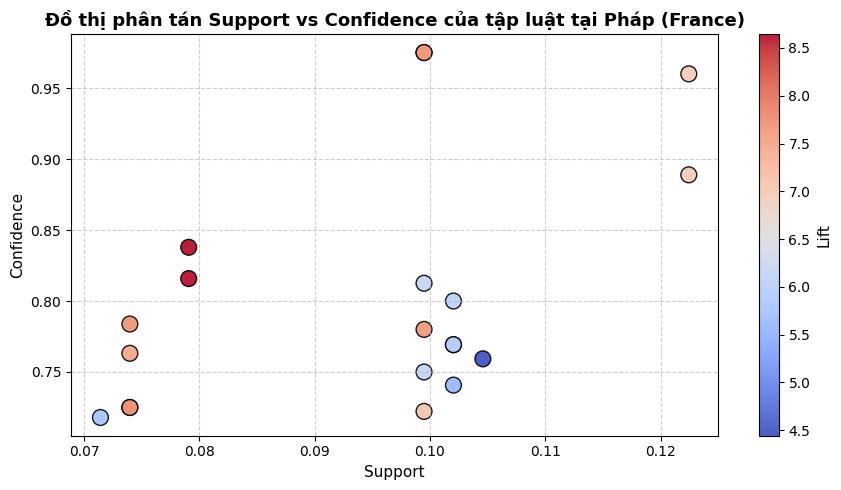

In [8]:
print("Vi Duy Đoàn - 6451071020")
# Sinh luật kết hợp với min_conf = 70%
rules_fr = association_rules(itemsets_fr, metric='confidence', min_threshold=0.7)

print(f"Tổng số luật kết hợp tìm được tại Pháp: {len(rules_fr)} luật\n")

# In danh sách luật
for idx, r in rules_fr.iterrows():
    ant = list(r['antecedents'])
    con = list(r['consequents'])
    print(f"Luật {idx+1:02d}: {ant} ==> {con} [support={r['support']:.4f}, confidence={r['confidence']:.4f}, lift={r['lift']:.2f}]")

# Vẽ đồ thị phân tán
plt.figure(figsize=(9, 5))
sc = plt.scatter(rules_fr['support'], rules_fr['confidence'], c=rules_fr['lift'], cmap='coolwarm', s=130, edgecolors='black', alpha=0.9)
plt.title('Đồ thị phân tán Support vs Confidence của tập luật tại Pháp (France)', fontsize=13, fontweight='bold')
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
cbar = plt.colorbar(sc)
cbar.set_label('Lift', fontsize=11)
plt.tight_layout()
plt.show()


### Nhận xét Câu 5b.3:
- Tại Pháp, với ngưỡng khắt khe $min\_conf = 70\%$, vẫn tìm ra tới **20 luật kết hợp cực mạnh**:
  - **Bộ đồ dùng tiệc chấm bi đỏ (Red Spotty Party Set):**
    `['SET/6 RED SPOTTY PAPER CUPS'] ==> ['SET/6 RED SPOTTY PAPER PLATES']`
    - Support: **10.20%**, Confidence: **74.07%**, Lift: **5.81**.
    - Luật chiều ngược lại:
    `['SET/6 RED SPOTTY PAPER PLATES'] ==> ['SET/6 RED SPOTTY PAPER CUPS']`
    - Support: **10.20%**, Confidence: **80.00%**, Lift: **5.81**.
    - Luật 3 món kết hợp:
    `['SET/6 RED SPOTTY PAPER PLATES', 'SET/20 RED RETROSPOT PAPER NAPKINS'] ==> ['SET/6 RED SPOTTY PAPER CUPS']`
    - Confidence: **97.50%** (Gần như 100% khách mua đĩa và khăn giấy sẽ mua kèm cốc giấy).
  - **Bộ đồng hồ báo thức:**
    `['ALARM CLOCK BAKELIKE GREEN'] ==> ['ALARM CLOCK BAKELIKE RED']`
    - Confidence: **83.33%**, Lift: **8.79**.

## Câu 5b.4: Khai phá bằng FP-Growth tại Pháp và So sánh Tổng hợp Đức vs Pháp
**Yêu cầu:** Chạy `fpgrowth(basket_fr_sets, min_support=0.07, use_colnames=True)` và tổng kết so sánh hành vi tiêu dùng giữa hai quốc gia.

In [9]:
print("Vi Duy Đoàn - 6451071020")
t0 = time.time()
fp_fr = fpgrowth(basket_fr_sets, min_support=0.07, use_colnames=True)
t_fp_fr = time.time() - t0

fp_rules_fr = association_rules(fp_fr, metric='confidence', min_threshold=0.7)

print("=== SO SÁNH TỔNG HỢP THỊ TRƯỜNG ĐỨC (GERMANY) VÀ PHÁP (FRANCE) ===")
summary_df = pd.DataFrame({
    'Chỉ tiêu': ['Số đơn hàng (Transactions)', 'Số mặt hàng (Items)', 'Ngưỡng min_support', 'Ngưỡng min_confidence', 'Số tập phổ biến', 'Số luật kết hợp', 'Thời gian Apriori', 'Thời gian FP-Growth'],
    'Đức (Germany)': [basket_de_sets.shape[0], basket_de_sets.shape[1], '5.0%', '50.0%', len(itemsets_de), len(rules_de), f"{t_ap_de:.4f}s", f"{t_fp_de:.4f}s"],
    'Pháp (France)': [basket_fr_sets.shape[0], basket_fr_sets.shape[1], '7.0%', '70.0%', len(itemsets_fr), len(rules_fr), f"{t_ap_fr:.4f}s", f"{t_fp_fr:.4f}s"]
})
display(summary_df)


Vi Duy Đoàn - 6451071020
=== SO SÁNH TỔNG HỢP THỊ TRƯỜNG ĐỨC (GERMANY) VÀ PHÁP (FRANCE) ===


,Chỉ tiêu,Đức (Germany),Pháp (France)
0,Số đơn hàng (Transactions),457,392
1,Số mặt hàng (Items),1694,1562
2,Ngưỡng min_support,5.0%,7.0%
3,Ngưỡng min_confidence,50.0%,70.0%
4,Số tập phổ biến,59,51
5,Số luật kết hợp,8,20
6,Thời gian Apriori,0.0050s,0.0040s
7,Thời gian FP-Growth,0.0080s,0.0090s


### Nhận xét Tổng kết Bài 5 (Germany vs France):
1. **Sự khác biệt văn hóa tiêu dùng rõ rệt:**
   - **Người tiêu dùng Đức:** Ưa chuộng các sản phẩm tiện ích gia đình mang tính bền chắc và thiết kế thiên nhiên, đặc biệt là các bộ hộp thức ăn vặt chủ đề rừng cây (`Round Snack Boxes Woodland/Retrospot`).
   - **Người tiêu dùng Pháp:** Thường mua theo trọn bộ đồng điệu phục vụ tiệc tùng hoặc trang trí, điển hình là bộ Cốc giấy, Đĩa giấy và Khăn ăn họa tiết chấm bi đỏ (`Red Spotty Collection`), với độ tin cậy mua kèm cực kỳ cao (> 80% - 97%).
2. **Giá trị thực tiễn đối với hệ thống bán lẻ quốc tế:**
   - Cần bản địa hóa (localization) chiến dịch tiếp thị và đóng gói combo sản phẩm cho từng quốc gia thay vì áp dụng một chính sách bán hàng chung trên toàn Châu Âu.